# Using `dfthcbe`

`dfthcbe` builds the qubitization walk operator of a DFTHC Hamiltonian (Low *et al.*, Phys. Rev. X **15**, 041016 (2025)) as a Qualtran bloq. This notebook shows what you can do with it: build the walk from a decomposed Hamiltonian, count its resources, simulate its parts, and check on $\text{H}_2$ that it block encodes the Hamiltonian. Its in-depth counterpart, [`dfthc_walk.ipynb`](dfthc_walk.ipynb), takes the walk apart step by step and explains why it is built the way it is.

In [1]:
import json

import numpy as np
import sympy
from cirq import dirac_notation
from qualtran import BloqBuilder, QAny
from qualtran.bloqs.basic_gates import IntEffect, IntState
from qualtran.bloqs.rotations.phase_gradient import PhaseGradientState
from qualtran.drawing import GraphvizCallGraph, show_bloq
from qualtran.resource_counting import (
    get_bloq_call_graph, get_cost_value, query_costs, QECGatesCost, QubitCount,
)

import matplotlib.pyplot as plt

from dfthcbe import (
    alias_probabilities, DFTHCBlockEncoding, DFTHCWalk, hamiltonian_matrix, reconstruct,
    walk_e_sos, walk_inputs, walk_integrals,
)
from dfthcbe.block_encoding import INNER_ANCILLAS, OUTER_ANCILLAS
from dfthcbe.prepare import UniformViaPhaseGradient

E0000 00:00:1793787253.849537   22915 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793787253.849593   22915 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_rejected' registered more than once. Ignoring later registration.
E0000 00:00:1793787253.849598   22915 instrument.cc:563] Metric with name 'grpc.resource_quota.connections_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793787253.849601   22915 instrument.cc:563] Metric with name 'grpc.resource_quota.instantaneous_memory_pressure' registered more than once. Ignoring later registration.
E0000 00:00:1793787253.849603   22915 instrument.cc:563] Metric with name 'grpc.resource_quota.memory_pressure_control_value' registered more than once. Ignoring later registration.


## 1. A walk from a Hamiltonian

A DFTHC-decomposed Hamiltonian is seven arrays, as `factors.npz` stores them: the unit vectors `U`, $(R, B, N)$, and the weights `W`, $(R, B, C)$, of its two-body part, the identity weights `w_B`, $(R, C)$, and the eigenpairs of its one-body part, `w_plus`, `u_plus` and `w_minus`, `u_minus`. 

`data/dfthc` has decomposed Hamiltonians of $\text{H}_2$, naphthalene, $\text{Fe}_2\text{S}_2$ and $\text{Fe}_4\text{S}_4$. `DFTHCWalk.from_factors` builds the walk from the factors, given the bits $b_{\mathrm{rot}}$ of each Givens angle and the bits $b_{k_1}$, $b_{k_2}$ of the outer and inner alias tables:

In [2]:
KEYS = ('U', 'W', 'w_B', 'w_plus', 'u_plus', 'w_minus', 'u_minus')


def load(name):
    """The factors of data/dfthc/<name>, as from_factors takes them, and the summary."""
    factors = np.load(f'../data/dfthc/{name}/factors.npz')
    summary = json.load(open(f'../data/dfthc/{name}/summary.json'))
    return {k: factors[k] for k in KEYS}, summary


fe4s4, summary = load('fe4s4')

In [3]:
# One option: set the bit precisions yourself
walk = DFTHCWalk.from_factors(**fe4s4, b_rot=15, b_k1=15, b_k2=15)
print(f"Lambda = {walk.block_encoding.Lambda:.4f}, "
      f"the factors' lambda_sos = {summary['lambda_sos']:.4f}")

Lambda = 50.7579, the factors' lambda_sos = 50.7010


The walk block encodes $H_{\mathrm{SA}} / \Lambda - I$, and $\Lambda$ is `lambda_sos` over $1 - P(\mathrm{succ}_{x_o} = 0)$: where the equal superposition over $x_o$ fails, the block is $-I$.

Instead of the bits of the two alias tables you can ask for a precision, each prepared probability within it of its target, and `from_factors` takes the bits this needs (Qualtran's `sub_bit_prec_from_epsilon`):

In [4]:
walk_eps = DFTHCWalk.from_factors(**fe4s4, b_rot=15, precision_outer=1e-4, precision_inner=1e-4)
print('b_k1 =', walk_eps.block_encoding.outer.b_k1, ', b_k2 =', walk_eps.block_encoding.inner.b_k2)

b_k1 = 7 , b_k2 = 10


## 2. Counting resources

Qualtran counts the gates of a bloq from its call graph, without building the circuit. `QECGatesCost` sorts them by kind:

In [5]:
print(get_cost_value(walk, QECGatesCost()))

toffoli: 385, cswap: 493, and_bloq: 5456, clifford: 248550, measurement: 5456


In [6]:
for name, w in [('W', walk), ('controlled W', walk.controlled())]:
    toffolis = get_cost_value(w, QECGatesCost()).total_toffoli_only()
    print(f'{name}: {toffolis} Toffolis, {get_cost_value(w, QubitCount())} qubits')

W: 6334 Toffolis, 898 qubits


controlled W: 6335 Toffolis, 899 qubits


Every decomposed Hamiltonian in `data/dfthc`, at the same bits:

In [7]:
for name in ('h2_sto3g_R2_B2_C1', 'h2_631g_R2_B3_C3', 'naphthalene', 'fe2s2', 'fe4s4'):
    f, _ = load(name)
    w = DFTHCWalk.from_factors(**f, b_rot=15, b_k1=15, b_k2=15)
    (R, B, N), C = f['U'].shape, f['W'].shape[2]
    toffolis = get_cost_value(w, QECGatesCost()).total_toffoli_only()
    print(f'{name:18s} N = {N:2d}, (R, B, C) = {(R, B, C)}: {toffolis:5d} Toffolis, '
          f'{get_cost_value(w, QubitCount())} qubits')

h2_sto3g_R2_B2_C1  N =  2, (R, B, C) = (2, 2, 1):   392 Toffolis, 129 qubits


h2_631g_R2_B3_C3   N =  4, (R, B, C) = (2, 3, 3):   679 Toffolis, 167 qubits


naphthalene        N = 10, (R, B, C) = (8, 6, 5):  1937 Toffolis, 358 qubits


fe2s2              N = 20, (R, B, C) = (6, 29, 15):  4412 Toffolis, 805 qubits


fe4s4              N = 36, (R, B, C) = (33, 11, 3):  6334 Toffolis, 898 qubits


The call graph shows where they go: the walk is the block encoding and a reflection, and the block encoding its parts, each with its Toffolis and qubits:

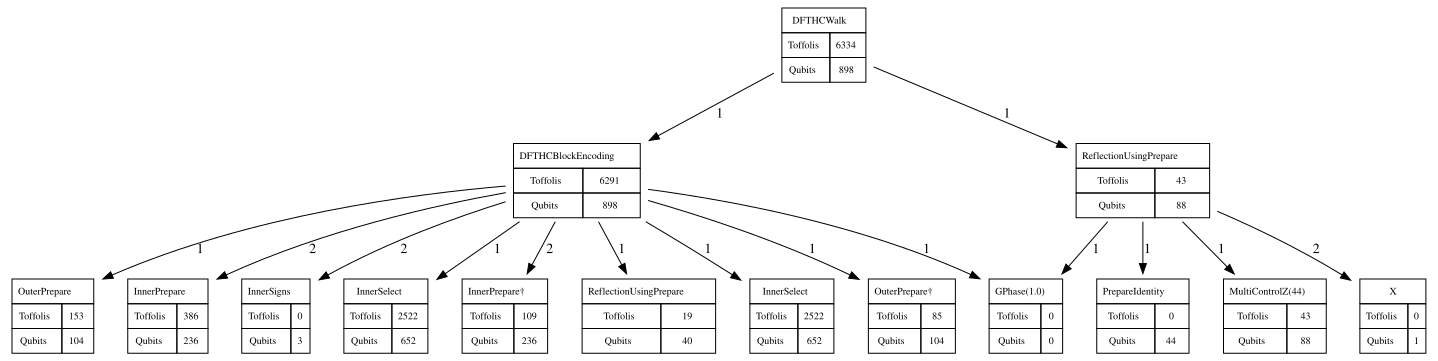

In [8]:
graph, _ = get_bloq_call_graph(walk, max_depth=2)
costs = query_costs(walk, [QECGatesCost(), QubitCount()])
labels = {bloq: {'Toffolis': costs[bloq][QECGatesCost()].total_toffoli_only(),
                 'Qubits': costs[bloq][QubitCount()]} for bloq in graph.nodes}
GraphvizCallGraph(graph, labels).get_svg()

**For any size.** `DFTHCWalk.symbolic` takes every size as a symbol and returns the Toffolis in closed form. Substituting the factors' sizes, and the block sizes `from_factors` chose, gives the count of the concrete circuit; here $\text{Fe}_4\text{S}_4$:

In [9]:
symbols = sympy.symbols('N R B C b_rot b_k1 b_k2 k_1 k_2 k_e1 k_e2 s_u')
toffolis = get_cost_value(DFTHCWalk.symbolic(*symbols), QECGatesCost()).total_toffoli_only()
be = walk.block_encoding
fe4s4 = dict(N=36, R=33, B=11, C=3, b_rot=15, b_k1=15, b_k2=15, s_u=7,
             k_1=be.outer.qroam.log_block_sizes[0], k_2=be.inner.qroam.log_block_sizes[1],
             k_e1=be.outer.qroam.erase_log_block_sizes[0],
             k_e2=be.inner.qroam.erase_log_block_sizes[0])
print(toffolis.subs(fe4s4))

6334


So you can explore sizes without building anything, for instance how the walk grows with the bits of the angles:

In [10]:
for b_rot in (10, 15, 20, 25):
    print(f'b_rot = {b_rot}: {toffolis.subs(fe4s4 | {"b_rot": b_rot})} Toffolis')

b_rot = 10: 4934 Toffolis
b_rot = 15: 6334 Toffolis
b_rot = 20: 7734 Toffolis
b_rot = 25: 9134 Toffolis


## 3. Simulating parts

Qualtran simulates a bloq classically if it only permutes basis states, and by tensor contraction if it is small.

**Classically.** A QROAM read is a permutation, so `call_classically` runs it on numbers. The outer alias read of $\text{Fe}_4\text{S}_4$ at the address $x_o = 5$ returns the table's $(\mathrm{alt}, \mathrm{keep})$ there, and its junk copies:

In [11]:
outer = walk.block_encoding.outer
outputs = {reg.name: np.zeros(reg.shape, dtype=int)  # all in |0> before the read
           for reg in outer.qroam.signature if reg.name != 'selection'}
x_o, alt, keep, *junk = outer.qroam.call_classically(selection=5, **outputs)
print(f'read: alt = {alt}, keep = {keep}; the table: alt = {outer.alt[5]}, keep = {outer.keep[5]}')

read: alt = 89, keep = 14376; the table: alt = 89, keep = 14376


and so at every address:

In [12]:
print(all(outer.qroam.call_classically(selection=x, **outputs)[1:3] == (outer.alt[x], outer.keep[x])
          for x in range(outer.num_x)))

True


The inner read is addressed by $(x_o, b)$, and also writes the rank $r = \lfloor x_o / C \rfloor$:

In [13]:
inner = walk.block_encoding.inner
outputs = {reg.name: np.zeros(reg.shape, dtype=int)
           for reg in inner.qroam.signature if not reg.name.startswith('selection')}
x_o, b, alt, keep, sgn, d_sgn, r, *junk = inner.qroam.call_classically(
    selection0=40, selection1=1, **outputs)
print(f'simulated:      alt = {alt}, keep = {keep}, sgn = {sgn}, d_sgn = {d_sgn}, r = {r}')
print(f'the true table: alt = {inner.alt[40][1]}, keep = {inner.keep[40][1]}, '
      f'sgn = {inner.sgn[40][1]}, d_sgn = {inner.d_sgn[40][1]}, r = {40 // inner.num_c}')


simulated:      alt = 6, keep = 2359, sgn = 1, d_sgn = 1, r = 13
the true table: alt = 6, keep = 2359, sgn = 1, d_sgn = 1, r = 13


**By tensor contraction.** A small part can be contracted to its matrix, or to the state it prepares. The equal superposition over $L = 6$ values at $s_u = 4$ rotation bits, started on $|0\rangle$ with the phase gradient $|\phi_4\rangle$ in and out:

In [14]:
L, s_u = 6, 4
uniform = UniformViaPhaseGradient(L, s=s_u)  # 3 qubits, the flag succ, a 4-qubit gradient

bb = BloqBuilder()
target, succ, phase_grad = bb.add(uniform, target=bb.add(IntState(0, int(np.ceil(np.log2(L))))),
                                  succ=bb.add(IntState(0, 1)),
                                  phase_grad=bb.add(PhaseGradientState(s_u)))
bb.add(PhaseGradientState(s_u).adjoint(), phase_grad=phase_grad)
psi = bb.finalize(target=target, succ=succ).tensor_contract()

print(dirac_notation(psi, decimals=3))
p = np.abs(psi.reshape(-1, 2)) ** 2  # row x, columns succ = 0 and 1
print(f'P[succ = 1] = {p[:, 1].sum():.4f}')

(-0.208+0.351j)|0001⟩ + (-0.208+0.351j)|0011⟩ + (-0.208+0.351j)|0101⟩ + (-0.208+0.351j)|0111⟩ + (-0.208+0.351j)|1001⟩ + (-0.208+0.351j)|1011⟩ + (0.01+0.024j)|1100⟩ + (0.01+0.024j)|1110⟩
P[succ = 1] = 0.9986


## 4. The block encoding of $\text{H}_2$ in STO-3G

For two orbitals the whole block encoding can be contracted. With the ancillas in $|0\rangle$ on both sides, what is left on the system registers `(psi_up, psi_dn)`, a $16 \times 16$ matrix, must be $H_{\mathrm{SA}} / \Lambda - I$. Two things make it small enough: few bits, $b_{\mathrm{rot}} = s_u = 4$ and $b_{k_1} = b_{k_2} = 2$; and `exact_erase=True`, which replaces each measurement-based erase by the exact inverse of its read, so the circuit is a unitary that can be contracted (it costs a second read, so it is for simulation only). The contraction takes about half a minute and a few GB of memory.

In [15]:
h2, summary_h2 = load('h2_sto3g_R2_B2_C1')
B_ROT, B_K1, B_K2, S = 4, 2, 2, 4
be = DFTHCBlockEncoding.from_factors(**h2, b_rot=B_ROT, b_k1=B_K1, b_k2=B_K2, s=S, exact_erase=True)

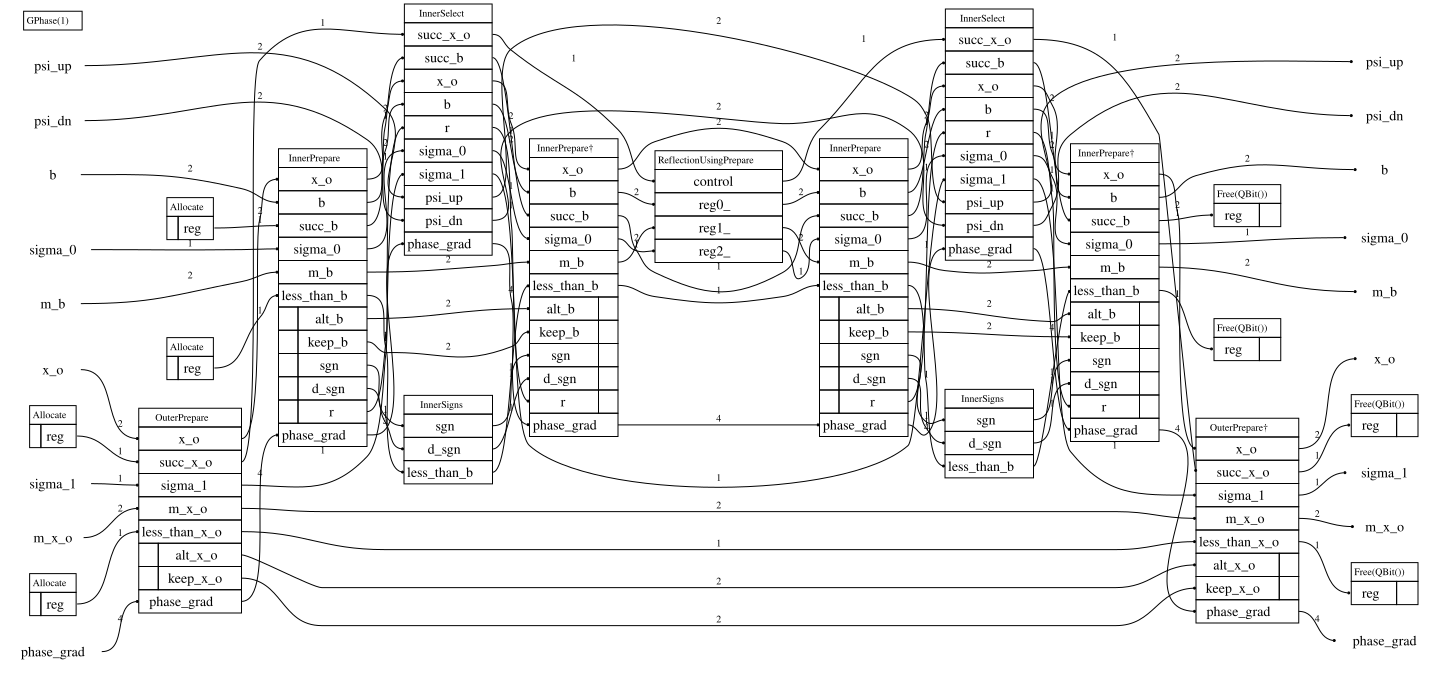

In [16]:
show_bloq(be.decompose_bloq())

In [17]:
# Simulate: heavy!
bb = BloqBuilder()
psi_up, psi_dn = bb.add_register('psi_up', QAny(2)), bb.add_register('psi_dn', QAny(2))
width = {name: be.signature.get_left(name).total_bits()
         for name in OUTER_ANCILLAS + INNER_ANCILLAS}
out = bb.add_d(be, psi_up=psi_up, psi_dn=psi_dn, phase_grad=bb.add(PhaseGradientState(B_ROT)),
               **{name: bb.add(IntState(0, n)) for name, n in width.items()})  # |0> in all ancillas
bb.add(PhaseGradientState(B_ROT).adjoint(), phase_grad=out.pop('phase_grad'))
for name, n in width.items():
    bb.add(IntEffect(0, n), val=out.pop(name))  # <0| out
block = bb.finalize(**out).tensor_contract()  # <0| BE |0> on (psi_up, psi_dn)

The Hamiltonian the circuit encodes is the decomposed Hamiltonian rounded to these bits, `encoded_factors()`, and `hamiltonian_matrix` writes it on the 16 Fock states of `(psi_up, psi_dn)`, with $|1\rangle$ occupied:

In [18]:
enc = be.encoded_factors()
e_sos = walk_e_sos(enc['W'], enc['w_B'], enc['w_minus'])

print(f'Encoded factors: {list(enc.keys())}')
print(f'E_SoS = {e_sos}')


Encoded factors: ['U', 'W', 'w_B', 'w_plus', 'u_plus', 'w_minus', 'u_minus']
E_SoS = -0.7164666932809745


In [19]:
H_SA = hamiltonian_matrix(*walk_integrals(**enc)) - e_sos * np.eye(16)
print(f'largest difference {np.abs(block - (H_SA / be.Lambda - np.eye(16))).max():.1e}')

largest difference 4.6e-15


They agree to machine precision: `encoded_factors()` also holds what a failed equal superposition does, over $b$ in $w_B$ and over $x_o$ in $\Lambda$.

**The energy.** In the two-electron sector the lowest eigenvalue of $H_{\mathrm{SA}}$ is the gap $E_0 - E_{\mathrm{SoS}}$, so the simulated block gives the ground-state energy:

In [20]:
two = [bin(i).count('1') == 2 for i in range(16)]  # the six Fock states with two electrons
H_sim = be.Lambda * (block + np.eye(16))  # H_SA, from the simulated circuit
gap_sim = np.linalg.eigvalsh(H_sim[np.ix_(two, two)])[0]
gap_true = np.linalg.eigvalsh(H_SA[np.ix_(two, two)])[0]
print(f"E_0 = {gap_sim + summary_h2['e_sos']:.4f} Ha from the walk, "
      f"{gap_true + summary_h2['e_sos']:.4f} Ha from the true H_SA, "
      f"{summary_h2['e_upper']:.4f} Ha from FCI (electronic)")

E_0 = -1.8309 Ha from the walk, -1.8309 Ha from the true H_SA, -1.8524 Ha from FCI (electronic)


The difference is the rounding of the angles and the alias tables to 4 and 2 bits. The encoded factors are known classically at any bits, so the error can be followed without simulating:

In [21]:
def error_h2(walk_h2):
    """E_0 - E_FCI of the Hamiltonian a walk of H2 encodes, from its Fock-space matrix."""
    enc = walk_h2.block_encoding.encoded_factors()
    e_sos = walk_e_sos(enc['W'], enc['w_B'], enc['w_minus'])
    H = hamiltonian_matrix(*walk_integrals(**enc)) - e_sos * np.eye(16)
    return np.linalg.eigvalsh(H[np.ix_(two, two)])[0] - summary_h2['e_gap']


errors_h2 = {}
for bits in range(4, 17, 2):
    walk_h2 = DFTHCWalk.from_factors(**h2, b_rot=bits, b_k1=bits, b_k2=bits, s=bits)
    errors_h2[bits] = error_h2(walk_h2)
    print(f'{bits:2d} bits: E_0 - E_FCI = {errors_h2[bits]:+.1e} Ha')

 4 bits: E_0 - E_FCI = +1.9e-02 Ha
 6 bits: E_0 - E_FCI = +1.1e-02 Ha
 8 bits: E_0 - E_FCI = -8.5e-04 Ha
10 bits: E_0 - E_FCI = +2.1e-04 Ha
12 bits: E_0 - E_FCI = +7.9e-05 Ha
14 bits: E_0 - E_FCI = +1.1e-05 Ha
16 bits: E_0 - E_FCI = -4.8e-06 Ha


Or with the angles and the equal superpositions at 16 bits and the two alias tables to a precision, which sets $b_{k_1}$ and $b_{k_2}$:

In [22]:
outer_w, inner_w = walk_inputs(h2['W'], h2['w_B'], h2['w_plus'], h2['w_minus'])
p_xo = outer_w / outer_w.sum()  # the outer distribution the factors ask for
q_b = np.abs(inner_w).reshape(-1, inner_w.shape[-1])
q_b = q_b / q_b.sum(axis=1, keepdims=True)  # the inner one, a row per (r, c)

for precision in (1e-2, 1e-4, 1e-6):
    walk_h2 = DFTHCWalk.from_factors(**h2, b_rot=16, precision_outer=precision,
                                     precision_inner=precision, s=16)
    be_h2 = walk_h2.block_encoding
    o, i = be_h2.outer, be_h2.inner
    err_p = np.abs(alias_probabilities(o.alt, o.keep, o.b_k1) - p_xo).max()
    err_q = max(np.abs(alias_probabilities(alt, keep, i.b_k2) - q).max()
                for alt, keep, q in zip(i.alt, i.keep, q_b))
    print(f'precision {precision:.0e}: b_k1 = {o.b_k1:2d}, b_k2 = {i.b_k2:2d}, '
          f'max |p - p~| = {err_p:.1e}, max |q - q~| = {err_q:.1e}, '
          f'E_0 - E_FCI = {error_h2(walk_h2):+.1e} Ha')

precision 1e-02: b_k1 =  5, b_k2 =  6, max |p - p~| = 1.5e-03, max |q - q~| = 2.4e-03, E_0 - E_FCI = -3.8e-04 Ha
precision 1e-04: b_k1 = 12, b_k2 = 12, max |p - p~| = 4.4e-06, max |q - q~| = 1.7e-05, E_0 - E_FCI = -8.7e-06 Ha
precision 1e-06: b_k1 = 18, b_k2 = 19, max |p - p~| = 3.5e-07, max |q - q~| = 1.7e-07, E_0 - E_FCI = -3.9e-06 Ha


The same works for systems far too large to simulate, where the Hamiltonians go to an FCI solver instead of `hamiltonian_matrix`. For naphthalene, 10 electrons in 10 orbitals, `reconstruct` gives the physical Hamiltonian of the factors, so its FCI energy is the factors' own; `walk_integrals` gives that of the walk, rounding included, in the factors' BLISS frame, so its FCI energy minus `walk_e_sos` is the gap $E_0 - E_{\mathrm{SoS}}$.

> **Warning:** the next three cells need pyscf (`pip install pyscf`), which `dfthcbe` does not install. They run eleven FCIs, about a minute.

In [23]:
from pyscf import fci

naph, summary_naph = load('naphthalene')
factors = np.load('../data/dfthc/naphthalene/factors.npz')
ints = np.load('../data/dfthc/naphthalene/integrals.npz')
nelec = (int(ints['nalpha']), int(ints['nbeta']))  # 5 + 5 electrons in 10 orbitals
solver = fci.direct_spin1.FCI()

h1e, eri = reconstruct(factors['U'], factors['W'], factors['h_sym'], factors['h1'])
e_factors = solver.kernel(h1e, eri, 10, nelec)[0]
print(f"the factors:  E_0 - E_FCI = {e_factors - summary_naph['e_upper']:+.1e} Ha")


def error_naph(walk_naph):
    """E_0 - E_FCI of the Hamiltonian a walk of naphthalene encodes, by FCI."""
    enc = walk_naph.block_encoding.encoded_factors()
    e_walk = solver.kernel(*walk_integrals(**enc), 10, nelec)[0]
    return e_walk - walk_e_sos(enc['W'], enc['w_B'], enc['w_minus']) - summary_naph['e_gap']


errors_naph = {}
for bits in range(4, 17, 2):
    walk_naph = DFTHCWalk.from_factors(**naph, b_rot=bits, b_k1=bits, b_k2=bits, s=bits)
    errors_naph[bits] = error_naph(walk_naph)
    print(f'{bits:2d} bits:  E_0 - E_FCI = {errors_naph[bits]:+.1e} Ha')

the factors:  E_0 - E_FCI = -1.7e-06 Ha


 4 bits:  E_0 - E_FCI = +3.5e-01 Ha


 6 bits:  E_0 - E_FCI = +3.8e-02 Ha


 8 bits:  E_0 - E_FCI = +1.6e-03 Ha


10 bits:  E_0 - E_FCI = +8.2e-05 Ha


12 bits:  E_0 - E_FCI = +5.1e-05 Ha


14 bits:  E_0 - E_FCI = +3.5e-05 Ha


16 bits:  E_0 - E_FCI = -1.7e-06 Ha


And with the alias tables to a precision:

In [24]:
for precision in (1e-2, 1e-4, 1e-6):
    walk_naph = DFTHCWalk.from_factors(**naph, b_rot=16, precision_outer=precision,
                                       precision_inner=precision, s=16)
    be_naph = walk_naph.block_encoding
    print(f'precision {precision:.0e}: b_k1 = {be_naph.outer.b_k1:2d}, '
          f'b_k2 = {be_naph.inner.b_k2:2d}, E_0 - E_FCI = {error_naph(walk_naph):+.1e} Ha')

precision 1e-02: b_k1 =  1, b_k2 =  4, E_0 - E_FCI = -9.1e-03 Ha


precision 1e-04: b_k1 =  8, b_k2 = 11, E_0 - E_FCI = -3.4e-06 Ha


precision 1e-06: b_k1 = 15, b_k2 = 18, E_0 - E_FCI = -2.6e-06 Ha


The two errors against the bits, with $b_{\mathrm{rot}} = b_{k_1} = b_{k_2}$:

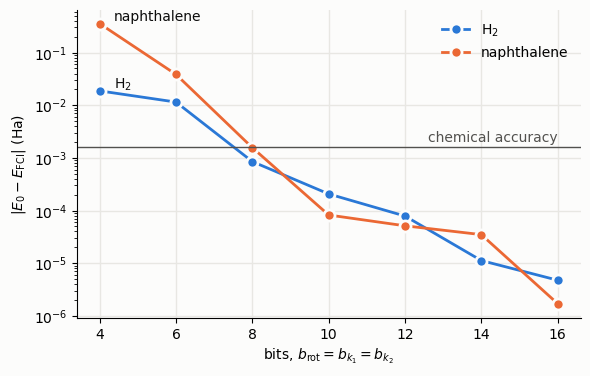

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 4), facecolor='#fcfcfb')
ax.set_facecolor('#fcfcfb')
series = [(r'H$_2$', errors_h2, '#2a78d6'), ('naphthalene', errors_naph, '#eb6834')]
for name, errors, color in series:
    bits, error = list(errors), np.abs(list(errors.values()))
    ax.plot(bits, error, '-o', color=color, lw=2, ms=8, mec='#fcfcfb', mew=2, label=name)
    ax.annotate(name, (bits[0], error[0]), xytext=(10, 2), textcoords='offset points',
                color='#0b0b0b')
ax.axhline(1.6e-3, color='#52514e', lw=1)
ax.annotate('chemical accuracy', (16, 1.6e-3), xytext=(0, 4), textcoords='offset points',
            ha='right', color='#52514e')
ax.set(yscale='log', xlabel=r'bits, $b_{\mathrm{rot}} = b_{k_1} = b_{k_2}$',
       ylabel=r'$|E_0 - E_{\mathrm{FCI}}|$ (Ha)')
ax.grid(color='#e8e7e3', lw=1)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()